# 01 Explore: H100 power traces and big drops
Loads the NLR GenAI power-profile dataset, shows example traces and characterises big-drop events. See `data/README_data.md` for the full data description.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
# make `src` importable whether the notebook runs from notebooks/ or the repo root
ROOT = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")
sys.path.insert(0, ROOT); os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

In [2]:
from src.load import load_traces
traces, meta = load_traces()
print(len(traces), 'samples in', len(meta), 'node-traces')
meta.groupby(['workload', 'node_count', 'split']).size().unstack(fill_value=0)

6090888 samples in 351 node-traces


split                               test  train  val
workload                node_count                  
inference_offline       1              3      8    3
inference_online_finite 1              4     12    4
inference_online_rate   1              4     11    3
train_llama2_70b_lora   2              2      6    2
                        4              4     12    4
                        8              8     32    8
                        16            16     48   16
train_stable_diffusion  1              1      3    1
                        2              2      8    2
                        4              4     12    4
                        8              8     24    8
                        16            16     32   16

## Example traces
Each trace is one 4-GPU node, sampled at 5 Hz. Red markers are detected big drops (power falls by more than 30% of the 10 s peak within 1 s).

cross-node drop synchronization: {'node_pairs_checked': 12481, 'matched_within_5s_pct': 97.58, 'median_skew_s': 0.0, 'p95_skew_s': 0.4, 'max_skew_s': 5.0, 'within_0_4s_pct': 98.73}
                         node_hours  n_drops  drops_per_node_hour  median_size_w  median_size_pct_of_peak  median_time_to_bottom_s  median_duration_s  p90_duration_s  median_ramp_max_wps  median_ramp_avg_wps
workload                                                                                                                                                                                                       
inference_offline              14.0     1588                113.4         1950.9                     75.4                      2.4                3.0             3.2               2090.9                861.0
inference_online_finite        19.9     1185                 59.5         1370.5                     63.7                      5.0               30.8            31.6               1468.2         

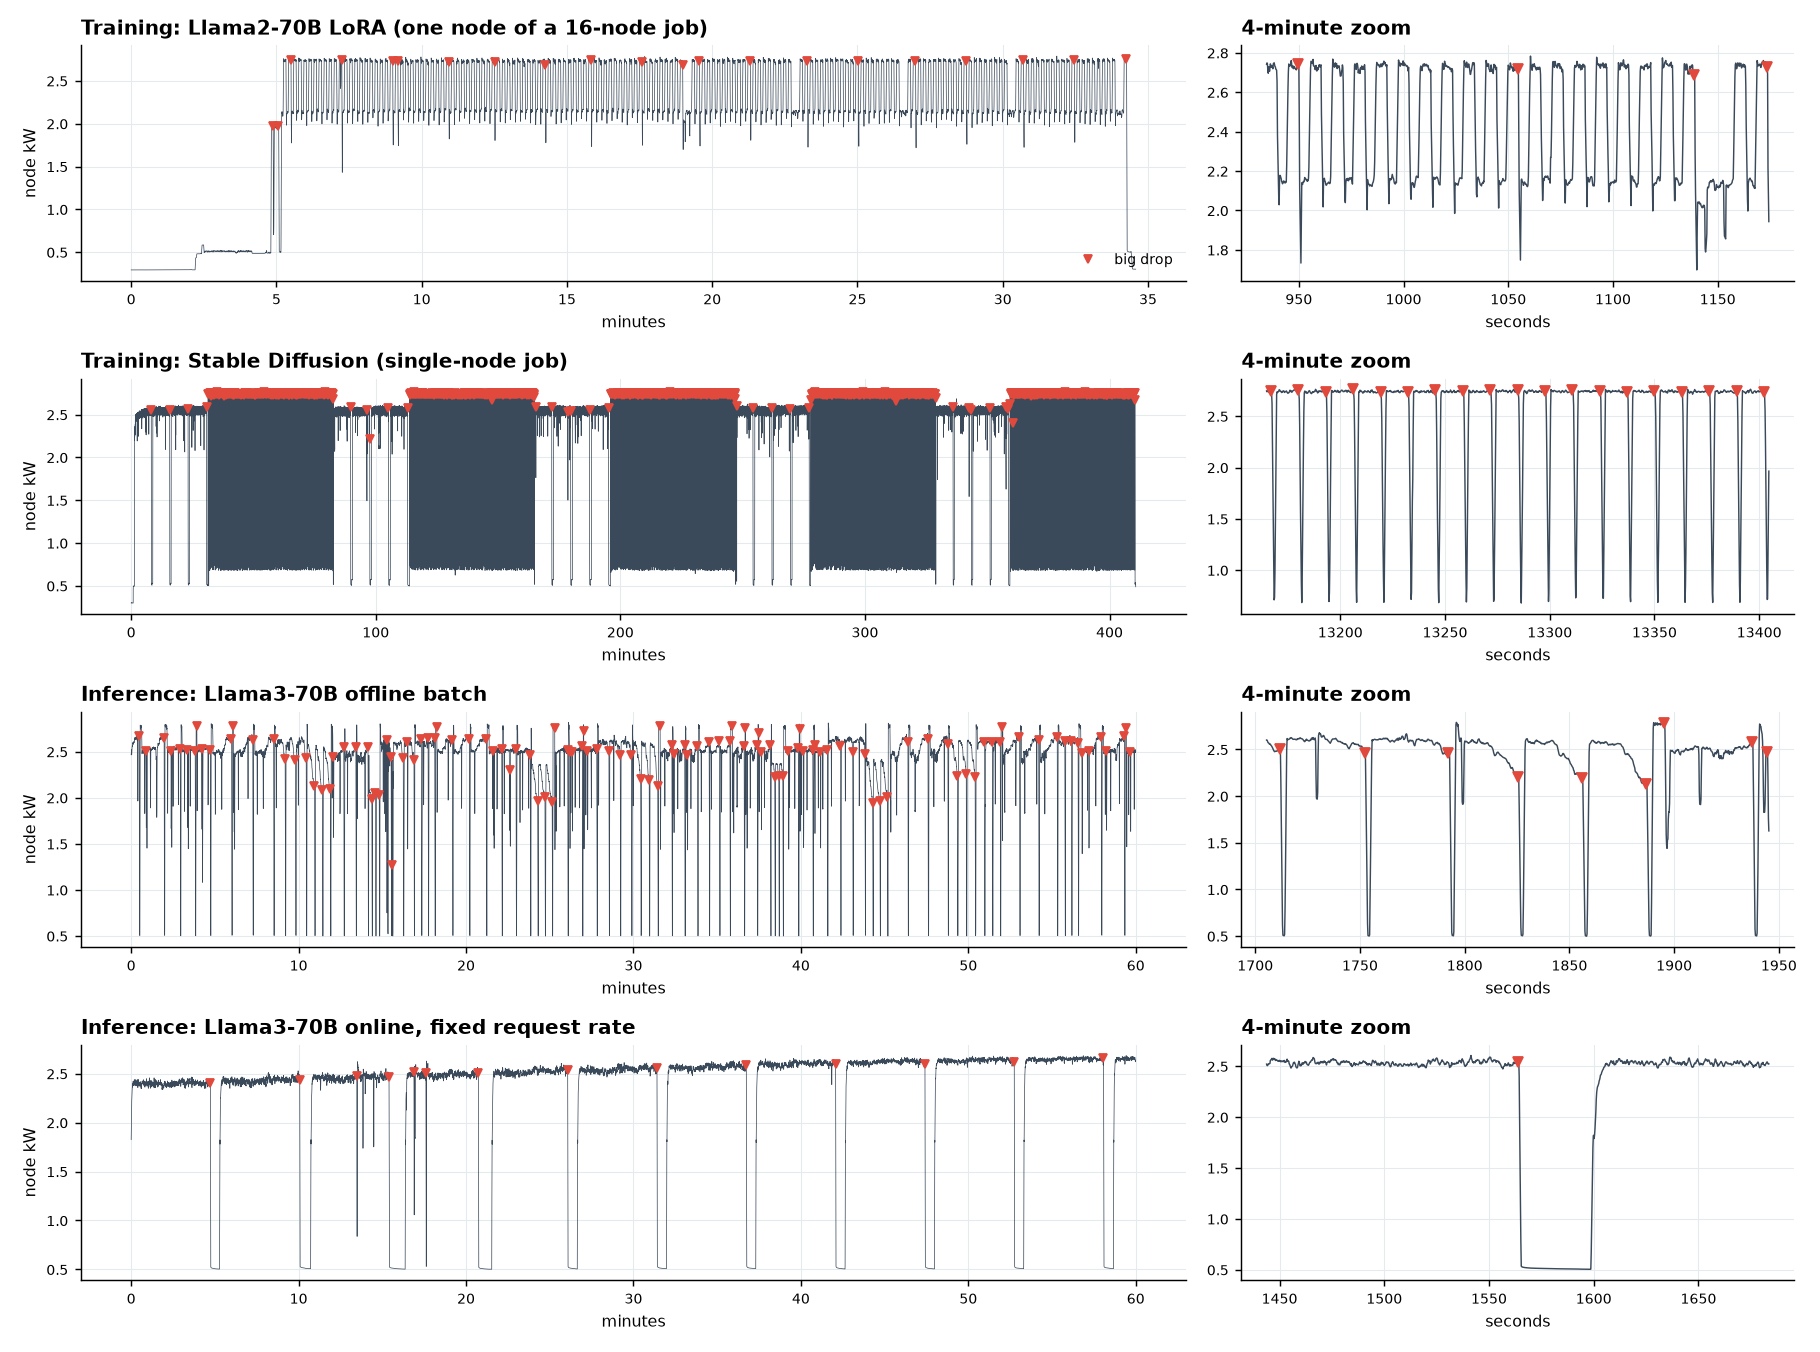

In [3]:
from src import explore
summ = explore.run()
display(Image('reports/figures/eda_sample_traces.png'))

## Single node vs whole multi-node job
All nodes of a training job swing at the same instant, so the job total is a scaled copy of one node.

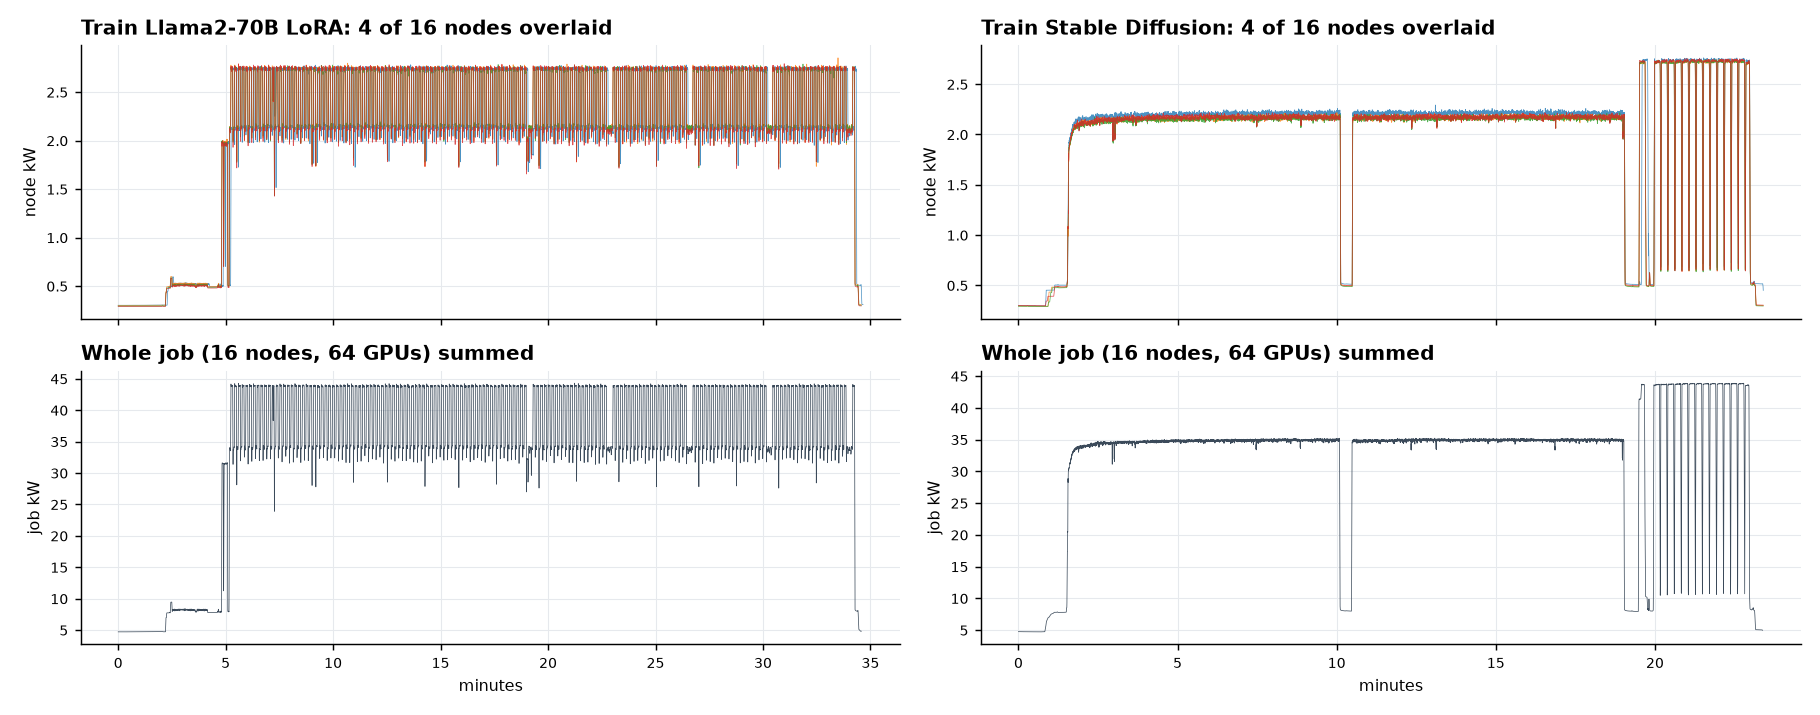

In [4]:
display(Image('reports/figures/eda_single_vs_multinode.png'))

## Big-drop statistics by workload

,node_hours,n_drops,drops_per_node_hour,median_size_w,median_size_pct_of_peak,median_time_to_bottom_s,median_duration_s,p90_duration_s,median_ramp_max_wps,median_ramp_avg_wps
workload,,,,,,,,,,
inference_offline,14.0,1588,113.4,1950.9,75.4,2.4,3.0,3.2,2090.9,861.0
inference_online_finite,19.9,1185,59.5,1370.5,63.7,5.0,30.8,31.6,1468.2,282.4
inference_online_rate,17.9,432,24.1,1361.8,55.8,3.8,4.4,42.8,2128.0,425.9
train_llama2_70b_lora,111.3,3590,32.3,1007.3,36.5,1.2,5.2,5.6,1821.4,839.0
train_stable_diffusion,175.2,20745,118.4,2060.2,74.9,1.6,2.4,9.2,2177.6,1269.8


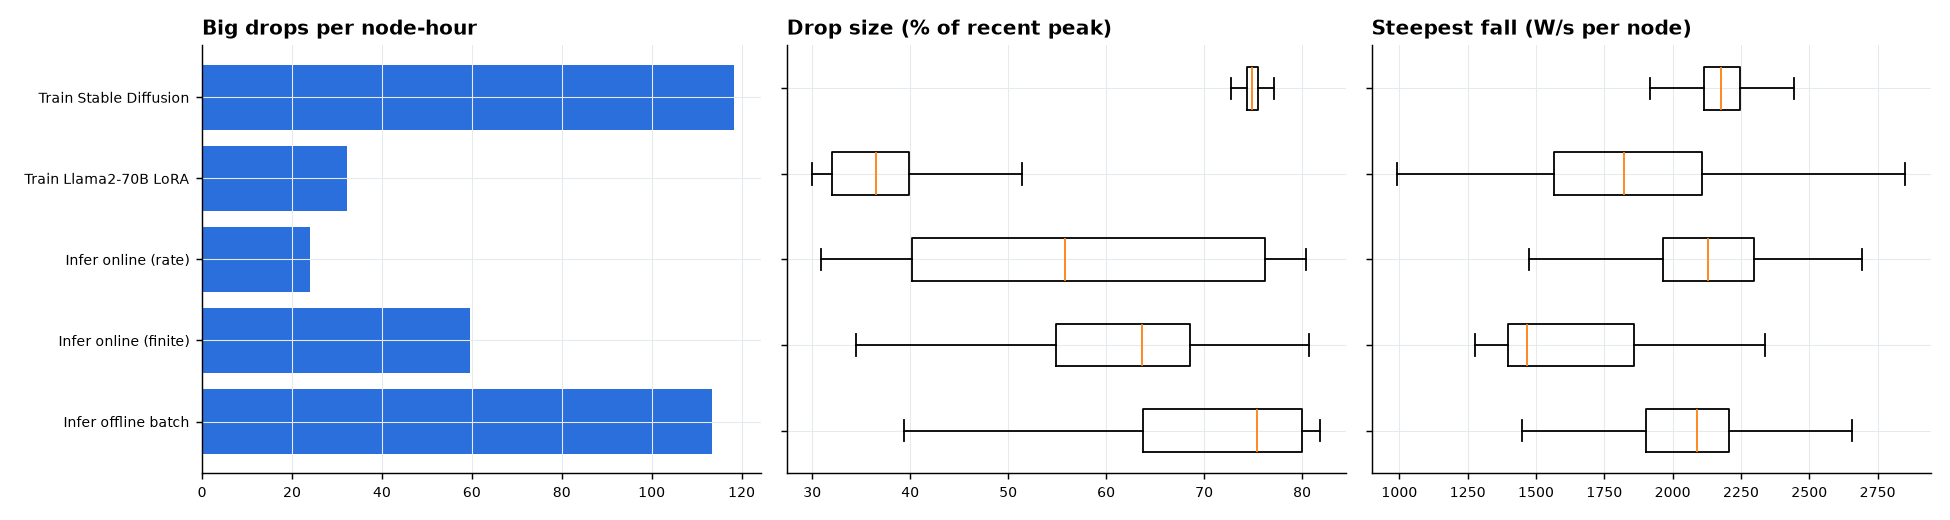

In [5]:
display(summ)
display(Image('reports/figures/eda_drop_stats.png'))

In [6]:
pd.read_csv('data/processed/drop_rate_by_nodes.csv')

,workload,node_count,drops_per_node_hour
0,inference_offline,1,113.4
1,inference_online_finite,1,59.5
2,inference_online_rate,1,24.1
3,train_llama2_70b_lora,2,17.4
4,train_llama2_70b_lora,4,10.9
5,train_llama2_70b_lora,8,27.2
6,train_llama2_70b_lora,16,49.4
7,train_stable_diffusion,1,175.3
8,train_stable_diffusion,2,171.2
9,train_stable_diffusion,4,112.5
